# 🚴‍♂️ Projeto Meituan — Previsão de Tempo de Entrega (ETA) [v3 Unificada]
### Modelagem Preditiva com Barreira Temporal, Padronização 100% em Manhattan ($L_1$), Seleção de Atributos, Target Embeddings & Benchmark Completo (Baseline Meituan vs Random Forest vs HistGradientBoosting vs LightGBM)

Este notebook consolida a arquitetura completa de previsão do tempo de entrega de refeições utilizando dados reais da **Meituan** (*INFORMS TSL Data-Driven Research Challenge 2024*).

---

### 🎯 Arquitetura em Dois Estágios Operacionais & Baseline Oficial
1. **Baseline Oficial da Meituan (`estimate_arrived_time`):**
   * A estimativa original calculada pela plataforma e exibida ao consumidor no momento da compra.
   * Contém uma **margem de segurança deliberada de ~8 a 9 minutos**, servindo como benchmark operacional conservador.
2. **Predição Instantânea no Checkout (`reduced_dataset`):**
   * **Quando roda:** No instante do clique de compra do cliente (`platform_order_time`).
   * **Finalidade:** Exibir a estimativa de entrega na tela antes de haver qualquer entregador alocado (sem dados de motorista).
   * **Features:** Distância de Manhattan restaurante-cliente ($L_1$), dia da semana, hora, componentes cíclicos contínuos (`sin`/`cos`), estimativa saneada de preparo da cozinha, distrito comercial e **Target Embedding do Restaurante (`poi_id`)**.
3. **Predição Dinâmica no Despacho/Aceite (`complete_dataset`):**
   * **Quando roda:** No instante em que o motorista aceita a corrida (`grab_time`).
   * **Finalidade:** Atualizar o rastreador dinâmico em tempo real com máxima precisão.
   * **Features adicionais:** Distância de Manhattan condutor-loja e jornada total em Manhattan, tempo decorrido até o aceite (`tempo_ate_aceite_min`), fila de despacho (`queue_wait_min`), sincronismo com a cozinha (`rem_prep_at_dispatch_min`), recusas prévias (`prior_rejections`), carga concorrente do condutor (`carga_entregador`), demanda recente no distrito (`da_demanda_20min`) e dinâmica de entrega em lote (`wave_em_andamento`, `pos_na_wave`).

---

### 📏 Padronização 100% em Métrica de Manhattan ($L_1$)
Em cidades reais, entregadores não voam em linha reta euclidiana ($L_2$). Todas as distâncias foram padronizadas na métrica viária em quarteirões ortogonais ($L_1$):
* `dist_rest_client_manhattan_km`: distância do restaurante até a casa do cliente.
* `dist_driver_rest_manhattan_km`: deslocamento do entregador até o restaurante para coleta.
* `dist_total_driver_trip_manhattan_km`: soma das duas etapas em quarteirões viários.

In [ ]:
# 1. Configuração do Ambiente e Importação de Bibliotecas
import sys
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
except ImportError:
    !pip install seaborn -q
    import seaborn as sns

try:
    import lightgbm as lgb
except ImportError:
    !pip install lightgbm -q
    import lightgbm as lgb

from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from IPython.display import display
except ImportError:
    display = print

# Configurações visuais e de precisão
pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False
})

TZ = pd.Timedelta(hours=8)  # Fuso horário local da operação da Meituan (China UTC+8)
COORD_SCALE = 1e6           # Fator de conversão das coordenadas de GPS

print("[OK] Ambiente configurado com sucesso! Bibliotecas de Machine Learning carregadas.")

[OK] Ambiente configurado com sucesso! Bibliotecas de Machine Learning carregadas.


---
## 📖 Dicionário de Dados Operacional (Base de Waybills Meituan)
Mapeamento formal dos 23 campos nativos da tabela de registros de entrega (`all_waybill_info_meituan_0322.csv`):

In [ ]:
# Dicionário de Dados Mapeado
dados_dicionario = {
    'Campo': [
        'dt', 'order_id', 'waybill_id', 'courier_id', 'da_id', 'is_courier_grabbed',
        'is_weekend', 'estimate_arrived_time', 'is_prebook', 'poi_id', 'sender_lng',
        'sender_lat', 'recipient_lng', 'recipient_lat', 'grab_lng', 'grab_lat',
        'dispatch_time', 'grab_time', 'fetch_time', 'arrive_time',
        'estimate_meal_prepare_time', 'order_push_time', 'platform_order_time'
    ],
    'Tradução': [
        'Data', 'ID do Pedido', 'ID da Guia', 'ID do Entregador', 'ID da Área', 'Entregador Aceitou',
        'É Final de Semana', 'Tempo Est. Chegada', 'É Agendado', 'ID do POI', 'Longitude Remetente',
        'Latitude Remetente', 'Longitude Destinatário', 'Latitude Destinatário', 'Longitude Aceite', 'Latitude Aceite',
        'Horário Despacho', 'Horário Aceite', 'Horário Coleta', 'Horário Chegada',
        'Tempo Est. Preparo', 'Horário Notificação', 'Horário Pedido'
    ],
    'Significado': [
        'Data do registro mapeado', 'Identificador único do pedido', 'Identificador da guia de transporte',
        'Identificador do entregador parceiro', 'Identificador da área/distrito de entrega', 'Indica se o entregador aceitou a rota (1) ou recusou (0)',
        'Identifica se o pedido ocorreu no fim de semana', 'Timestamp prometido para a chegada ao destino', 'Indica se o pedido foi agendado previamente',
        'Identificador do estabelecimento/restaurante', 'Coordenada de longitude do remetente', 'Coordenada de latitude do remetente',
        'Coordenada de longitude do destinatário', 'Coordenada de latitude do destinatário', 'Coordenada de longitude onde aceitou a rota',
        'Coordenada de latitude onde aceitou a rota', 'Timestamp de quando o pedido foi despachado', 'Timestamp de quando o entregador aceitou',
        'Timestamp de quando o entregador coletou', 'Timestamp da entrega concluída no destino', 'Tempo estimado para o preparo da refeição',
        'Timestamp de envio da notificação ao sistema', 'Timestamp de criação do pedido na plataforma'
    ],
    'Tipo': [
        'Integer', 'Integer', 'Integer', 'Integer', 'Integer', 'Integer',
        'Integer', 'Integer', 'Integer', 'Integer', 'Float',
        'Float', 'Float', 'Float', 'Float', 'Float',
        'Integer', 'Integer', 'Integer', 'Integer', 'Integer', 'Integer', 'Integer'
    ]
}

df_dicionario = pd.DataFrame(dados_dicionario)
display(df_dicionario)

,Campo,Tradução,Significado,Tipo
0,dt,Data,Data do registro mapeado,Integer
1,order_id,ID do Pedido,Identificador único do pedido,Integer
2,waybill_id,ID da Guia,Identificador da guia de transporte,Integer
3,courier_id,ID do Entregador,Identificador do entregador parceiro,Integer
4,da_id,ID da Área,Identificador da área/distrito de entrega,Integer
5,is_courier_grabbed,Entregador Aceitou,Indica se o entregador aceitou a rota (1) ou r...,Integer
6,is_weekend,É Final de Semana,Identifica se o pedido ocorreu no fim de semana,Integer
7,estimate_arrived_time,Tempo Est. Chegada,Timestamp prometido para a chegada ao destino,Integer
8,is_prebook,É Agendado,Indica se o pedido foi agendado previamente,Integer
9,poi_id,ID do POI,Identificador do estabelecimento/restaurante,Integer


---
## 1. Bloco de Carga de Dados Relacionais & EDA Retrospectivo

In [ ]:
# Carregamento das Bases de Dados
DATA_DIR = '.'
F_WAYBILL = os.path.join(DATA_DIR, 'all_waybill_info_meituan_0322.csv')
F_WAVE = os.path.join(DATA_DIR, 'courier_wave_info_meituan.csv')

print("Carregando bases de dados Meituan...")
t0 = time.time()
df_raw = pd.read_csv(F_WAYBILL)
print(f"[OK] Base Waybills: {df_raw.shape[0]:,} linhas × {df_raw.shape[1]} colunas ({time.time() - t0:.2f}s)")

# Carga de Waves (se disponível)
df_wave_raw = None
if os.path.exists(F_WAVE):
    df_wave_raw = pd.read_csv(F_WAVE)
    print(f"[OK] Base Waves: {df_wave_raw.shape[0]:,} linhas × {df_wave_raw.shape[1]} colunas")
else:
    print("[Aviso] Arquivo de waves não encontrado na pasta local.")

# Pré-cálculo de tentativas de despacho (prior_rejections) ordenando pelo pedido e tempo de despacho
print("Pré-calculando histórico cumulativo de tentativas anteriores (prior_rejections)...")
df_raw = df_raw.sort_values(['order_id', 'dispatch_time']).reset_index(drop=True)
df_raw['prior_rejections'] = df_raw.groupby('order_id').cumcount()
print(f"[OK] Pedidos com múltiplas tentativas: {(df_raw['prior_rejections'] > 0).sum():,} waybills")

Carregando bases de dados Meituan...
[OK] Base Waybills: 654,343 linhas × 24 colunas (1.36s)
[OK] Base Waves: 206,748 linhas × 6 colunas
Pré-calculando histórico cumulativo de tentativas anteriores (prior_rejections)...
[OK] Pedidos com múltiplas tentativas: 85,797 waybills


=== RESUMO EXPLORATÓRIO BASAL ===
Taxa de Aceite:   86.9% aceitos | 13.1% recusados
Tipo de Pedido:   96.3% imediatos | 3.7% agendados
Entidades Únicas: 568,546 pedidos | 4,962 restaurantes | 4,955 entregadores


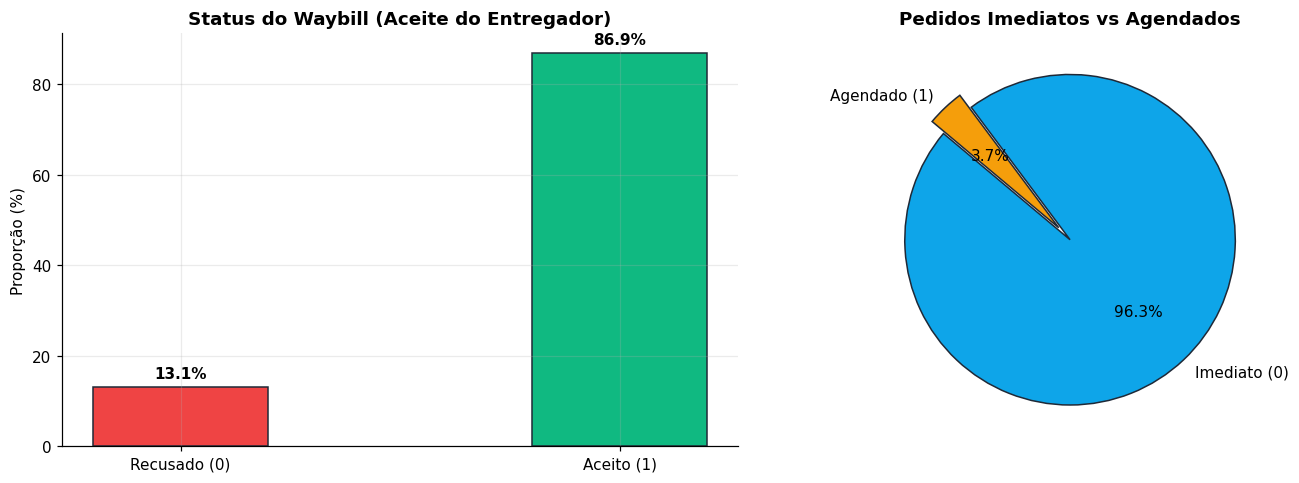

In [ ]:
# Estatísticas Descritivas e Visualização Rápida de EDA
grab_dist = df_raw['is_courier_grabbed'].value_counts(normalize=True) * 100
prebook_dist = df_raw['is_prebook'].value_counts(normalize=True) * 100

print("=" * 65)
print("=== RESUMO EXPLORATÓRIO BASAL ===")
print("=" * 65)
print(f"Taxa de Aceite:   {grab_dist.get(1, 0):.1f}% aceitos | {grab_dist.get(0, 0):.1f}% recusados")
print(f"Tipo de Pedido:   {prebook_dist.get(0, 0):.1f}% imediatos | {prebook_dist.get(1, 0):.1f}% agendados")
print(f"Entidades Únicas: {df_raw['order_id'].nunique():,} pedidos | {df_raw['poi_id'].nunique():,} restaurantes | {df_raw['courier_id'].nunique():,} entregadores")
print("=" * 65)

# Gráficos de Proporções Iniciais
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(['Recusado (0)', 'Aceito (1)'], [grab_dist.get(0, 0), grab_dist.get(1, 0)], color=['#ef4444', '#10b981'], edgecolor='#1f2937', width=0.4)
axes[0].set_title('Status do Waybill (Aceite do Entregador)', fontweight='bold')
axes[0].set_ylabel('Proporção (%)')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 2), ha='center', fontweight='bold')

axes[1].pie(prebook_dist, labels=['Imediato (0)', 'Agendado (1)'], autopct='%1.1f%%', colors=['#0ea5e9', '#f59e0b'], startangle=140, explode=(0, 0.1), wedgeprops={'edgecolor': '#1f2937'})
axes[1].set_title('Pedidos Imediatos vs Agendados', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 2. Bloco de Saneamento Rigoroso & Remoção de Zeros Sentinela

A plataforma Meituan utiliza o valor $0$ como indicador sentinela de registros ausentes ou inconsistentes:
1. **O Erro Crítico do Preparo da Cozinha:** $7.444$ entregas aceitas tinham `estimate_meal_prepare_time = 0`. Sem remoção, a subtração gerava anomalias de **$-27{,}7$ milhões de minutos**, distorcendo os particionamentos das árvores.
2. **Coordenadas Zeradas ($= 0$):** Indicam perda de sinal GPS.
3. **Filtros de Coerência e Duração:** Remoção de agendados (`is_prebook == 1`), waybills recusados (`is_courier_grabbed == 0`) e limitação a entregas entre **5 e 90 minutos**.

In [ ]:
# Execução do Saneamento Rigoroso de Dados
n_total = len(df_raw)

# 1. Apenas waybills aceitos
df_clean = df_raw[df_raw['is_courier_grabbed'] == 1].copy()
n_grabbed = len(df_clean)

# 2. Apenas pedidos imediatos (remover agendados)
df_clean = df_clean[df_clean['is_prebook'] == 0].copy()
n_prebook = len(df_clean)

# 3. Descarte de Zeros Sentinela em Carimbos Temporais
time_cols_used = [
    'platform_order_time', 'dispatch_time', 'estimate_meal_prepare_time',
    'estimate_arrived_time', 'arrive_time', 'grab_time'
]
for col in time_cols_used:
    df_clean = df_clean[df_clean[col] > 0]
n_time_sentinel = len(df_clean)

# 4. Descarte de Zeros Sentinela em Coordenadas Geográficas
coord_cols_used = ['sender_lat', 'sender_lng', 'recipient_lat', 'recipient_lng', 'grab_lat', 'grab_lng']
for col in coord_cols_used:
    df_clean = df_clean[df_clean[col] > 0]
n_coord_sentinel = len(df_clean)

# 5. Coerência Cronológica e Limites de Duração (5 a 90 min)
df_clean = df_clean[df_clean['dispatch_time'] >= df_clean['platform_order_time']]
df_clean = df_clean[df_clean['arrive_time'] > df_clean['dispatch_time']]
df_clean['temp_total_time_min'] = (df_clean['arrive_time'] - df_clean['platform_order_time']) / 60.0
df_clean = df_clean[(df_clean['temp_total_time_min'] >= 5.0) & (df_clean['temp_total_time_min'] <= 90.0)].copy()
n_clean = len(df_clean)

# Relatório Formatado para o Relatório 4
print("=" * 75)
print("=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: SANEAMENTO DE DADOS ===")
print("=" * 75)
print(f"Total Bruto Inicial:                       {n_total:,} registros (100.0%)")
print(f"Após remover recusas (grabbed=0):          {n_grabbed:,} registros ({n_grabbed/n_total*100:.1f}%)")
print(f"Após remover agendados (prebook=1):        {n_prebook:,} registros ({n_prebook/n_total*100:.1f}%)")
print(f"Após remover Zeros Sentinela em Tempos:    {n_time_sentinel:,} registros ({n_time_sentinel/n_total*100:.1f}%)")
print(f"Após remover Zeros Sentinela em GPS:       {n_coord_sentinel:,} registros ({n_coord_sentinel/n_total*100:.1f}%)")
print(f"Total Final Válido, Limpo e Consistente:   {n_clean:,} registros ({n_clean/n_total*100:.1f}%)")
print(f"Total de Registros Eliminados (Ruído):     {n_total - n_clean:,} registros ({(n_total - n_clean)/n_total*100:.1f}%)")
print("=" * 75)

=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: SANEAMENTO DE DADOS ===
Total Bruto Inicial:                       654,343 registros (100.0%)
Após remover recusas (grabbed=0):          568,546 registros (86.9%)
Após remover agendados (prebook=1):        546,365 registros (83.5%)
Após remover Zeros Sentinela em Tempos:    538,920 registros (82.4%)
Após remover Zeros Sentinela em GPS:       538,920 registros (82.4%)
Total Final Válido, Limpo e Consistente:   538,435 registros (82.3%)
Total de Registros Eliminados (Ruído):     115,908 registros (17.7%)


---
## 3. Bloco de Engenharia de Features: Padronização 100% em Manhattan ($L_1$)

Nesta etapa, calculamos **todas as métricas espaciais exclusivamente com a distância de Manhattan ($L_1$)**:

$$\text{Distância Manhattan}(A, B) = |\Delta\text{lat}| \times 111{,}32 + |\Delta\text{lng}| \times 111{,}32 \times \cos(\text{lat}_{\text{média}})$$

### Métricas Criadas:
1. `dist_rest_client_manhattan_km`: Restaurante $\to$ Cliente.
2. `dist_driver_rest_manhattan_km`: Entregador $\to$ Restaurante no aceite.
3. `dist_total_driver_trip_manhattan_km`: Soma da rota completa do entregador em quarteirões viários (`dist_driver_rest_manhattan_km + dist_rest_client_manhattan_km`).
4. **Features Temporais e Cíclicas:** Hora local (UTC+8), dia da semana, fim de semana, e componentes contínuos `sin_order_hour` e `cos_order_hour`.
5. **Latências Operacionais e Cozinha:**
   * `est_meal_prep_min`: Tempo previsto de preparo da cozinha.
   * `queue_wait_min`: Tempo represado na fila de despacho até a oferta.
   * `tempo_ate_aceite_min`: Tempo total transcorrido desde o clique de compra até o entregador aceitar a rota.
   * `rem_prep_at_dispatch_min`: Sincronismo entre previsão de cozinha e instante do despacho.
6. **Métricas de Dinâmica de Operação:**
   * `carga_entregador`: Quantidade de pedidos na mochila do condutor no momento do aceite (busca binária vetorizada `np.searchsorted`).
   * `da_demanda_20min`: Volume de pedidos despachados no distrito nos 20 minutos anteriores.
   * `wave_em_andamento` e `pos_na_wave`: Integração relacional de entregas em lote.

In [ ]:
# 1. Definição do Target e Baseline
df_clean['target_total_time_min'] = (df_clean['arrive_time'] - df_clean['platform_order_time']) / 60.0
df_clean['meituan_baseline_min'] = (df_clean['estimate_arrived_time'] - df_clean['platform_order_time']) / 60.0

# 2. PADRONIZAÇÃO 100% EM MANHATTAN (L1)
mean_lat_rad = np.radians(df_clean['sender_lat'].mean() / COORD_SCALE)

def calc_manhattan_dist_km(lat1, lng1, lat2, lng2, mean_lat_r):
    dlat = np.abs((lat2 - lat1) / COORD_SCALE * 111.32)
    dlng = np.abs((lng2 - lng1) / COORD_SCALE * 111.32 * np.cos(mean_lat_r))
    return dlat + dlng

# Distâncias 100% em Manhattan
df_clean['dist_rest_client_manhattan_km'] = calc_manhattan_dist_km(
    df_clean['sender_lat'], df_clean['sender_lng'],
    df_clean['recipient_lat'], df_clean['recipient_lng'], mean_lat_rad
)
df_clean['dist_driver_rest_manhattan_km'] = calc_manhattan_dist_km(
    df_clean['grab_lat'], df_clean['grab_lng'],
    df_clean['sender_lat'], df_clean['sender_lng'], mean_lat_rad
)
df_clean['dist_total_driver_trip_manhattan_km'] = (
    df_clean['dist_driver_rest_manhattan_km'] + df_clean['dist_rest_client_manhattan_km']
)

# 3. Conversão Temporal para Horário Local (China UTC+8) e Cíclico
order_dt_local = pd.to_datetime(df_clean['platform_order_time'], unit='s') + TZ
df_clean['order_hour'] = order_dt_local.dt.hour
df_clean['day_of_week'] = order_dt_local.dt.dayofweek
df_clean['is_friday'] = (order_dt_local.dt.dayofweek == 4).astype(int)

minuto_do_dia = df_clean['order_hour'] * 60 + order_dt_local.dt.minute
df_clean['sin_order_hour'] = np.sin(2 * np.pi * minuto_do_dia / 1440.0)
df_clean['cos_order_hour'] = np.cos(2 * np.pi * minuto_do_dia / 1440.0)

# 4. Latências Operacionais e Sincronismo
df_clean['est_meal_prep_min'] = (df_clean['estimate_meal_prepare_time'] - df_clean['platform_order_time']) / 60.0
df_clean['queue_wait_min'] = (df_clean['dispatch_time'] - df_clean['platform_order_time']) / 60.0
df_clean['rem_prep_at_dispatch_min'] = (df_clean['estimate_meal_prepare_time'] - df_clean['dispatch_time']) / 60.0
df_clean['tempo_ate_aceite_min'] = (df_clean['grab_time'] - df_clean['platform_order_time']) / 60.0

# 5. Carga Concorrente do Entregador (Sem Data Leakage)
print("Calculando carga concorrente do entregador no instante do aceite...")
t0 = time.time()
df_clean = df_clean.sort_values('grab_time').reset_index(drop=True)
carga_arr = np.zeros(len(df_clean), dtype=np.int32)
for _, pos in df_clean.groupby('courier_id').indices.items():
    g = df_clean.iloc[pos]
    ini = np.sort(g['grab_time'].values)
    fim = np.sort(g['arrive_time'].values)
    t = g['grab_time'].values
    carga_arr[pos] = np.searchsorted(ini, t, 'left') - np.searchsorted(fim, t, 'right')
df_clean['carga_entregador'] = carga_arr

# 6. Demanda Recente no Distrito (Últimos 20 min)
print("Calculando pressão de demanda recente no distrito (da_demanda_20min)...")
t0 = time.time()
JANELA_SEG = 20 * 60
demanda_arr = np.zeros(len(df_clean), dtype=np.int32)
for _, pos in df_clean.groupby('da_id').indices.items():
    g = df_clean.iloc[pos]
    push = np.sort(g['order_push_time'].values)
    t = g['grab_time'].values
    demanda_arr[pos] = (np.searchsorted(push, t, 'right') - np.searchsorted(push, t - JANELA_SEG, 'left'))
df_clean['da_demanda_20min'] = demanda_arr

# 7. Fusão de Waves
if df_wave_raw is not None:
    print("Integrando informações de Waves...")
    w2 = df_wave_raw.copy()
    w2['order_list'] = w2['order_ids'].str.strip('[]').str.split(', ')
    wave_longa = w2[['dt', 'courier_id', 'wave_id', 'wave_start_time', 'order_list']].explode('order_list')
    wave_longa = wave_longa[wave_longa['order_list'].str.len() > 0].copy()
    wave_longa['order_id'] = wave_longa['order_list'].astype('int64')
    wave_longa = wave_longa.drop(columns='order_list').drop_duplicates(['order_id', 'courier_id'])

    df_clean = df_clean.merge(wave_longa[['order_id', 'courier_id', 'wave_id', 'wave_start_time']], on=['order_id', 'courier_id'], how='left')
    df_clean['wave_em_andamento'] = (df_clean['grab_time'] > df_clean['wave_start_time']).fillna(0).astype(int)
    df_clean['pos_na_wave'] = (df_clean.sort_values('grab_time').groupby(['dt', 'courier_id', 'wave_id']).cumcount().reindex(df_clean.index)).fillna(0).astype(int)
else:
    df_clean['wave_em_andamento'] = 0
    df_clean['pos_na_wave'] = 0

print("\n" + "=" * 75)
print("=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: ESTATÍSTICAS MANHATTAN ===")
print("=" * 75)
print(f"Distância Restaurante -> Cliente (Manhattan): Média = {df_clean['dist_rest_client_manhattan_km'].mean():.2f} km | Máx = {df_clean['dist_rest_client_manhattan_km'].max():.2f} km")
print(f"Distância Entregador -> Restaurante (Manhattan): Média = {df_clean['dist_driver_rest_manhattan_km'].mean():.2f} km | Máx = {df_clean['dist_driver_rest_manhattan_km'].max():.2f} km")
print(f"Jornada Total da Viagem (Manhattan):          Média = {df_clean['dist_total_driver_trip_manhattan_km'].mean():.2f} km | Máx = {df_clean['dist_total_driver_trip_manhattan_km'].max():.2f} km")
print("=" * 75)

Calculando carga concorrente do entregador no instante do aceite...
Calculando pressão de demanda recente no distrito (da_demanda_20min)...
Integrando informações de Waves...

=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: ESTATÍSTICAS MANHATTAN ===
Distância Restaurante -> Cliente (Manhattan): Média = 2.00 km | Máx = 19.39 km
Distância Entregador -> Restaurante (Manhattan): Média = 0.74 km | Máx = 23.40 km
Jornada Total da Viagem (Manhattan):          Média = 2.74 km | Máx = 23.71 km


---
## 4. Bloco de Target Encoding K-Fold Regularizado para Restaurantes (`poi_id`)

Com $4.962$ estabelecimentos distintos, evitamos a esparsidade de 5 mil colunas aplicando **Target Encoding com suavização Bayesiana e validação cruzada out-of-fold em 5 folds**, impedindo estritamente qualquer vazamento de dados (*data leakage*).

In [ ]:
# Implementação do Target Encoding K-Fold Regularizado para poi_id
print("Calculando Target Encoding regularizado para poi_id (K-Fold Out-of-Fold)...")
smooth_m = 10.0
global_mean_time = df_clean['target_total_time_min'].mean()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
df_clean['poi_target_enc'] = np.nan

for tr_idx, val_idx in kf.split(df_clean):
    f_tr = df_clean.iloc[tr_idx]
    stats = f_tr.groupby('poi_id')['target_total_time_min'].agg(['count', 'mean'])
    smoothed = (stats['count'] * stats['mean'] + smooth_m * global_mean_time) / (stats['count'] + smooth_m)
    df_clean.iloc[val_idx, df_clean.columns.get_loc('poi_target_enc')] = df_clean.iloc[val_idx]['poi_id'].map(smoothed)

df_clean['poi_target_enc'] = df_clean['poi_target_enc'].fillna(global_mean_time)

print("=" * 75)
print("=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: TARGET ENCODING POI ===")
print("=" * 75)
print(f"Total de Restaurantes Mapeados: {df_clean['poi_id'].nunique():,}")
print(f"Média Geral da Variável-Alvo:    {global_mean_time:.2f} minutos")
print(f"Média do poi_target_enc:        {df_clean['poi_target_enc'].mean():.2f} min (Std: {df_clean['poi_target_enc'].std():.2f} min)")
print("=" * 75)

Calculando Target Encoding regularizado para poi_id (K-Fold Out-of-Fold)...
=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: TARGET ENCODING POI ===
Total de Restaurantes Mapeados: 4,923
Média Geral da Variável-Alvo:    29.46 minutos
Média do poi_target_enc:        29.50 min (Std: 5.40 min)


---
## 5. Bloco de Seleção de Atributos & Teste Empírico de Impacto

### 🔍 Metodologia de Seleção:
1. **Padronização em Manhattan:** Descartam-se todas as distâncias euclidianas parciais e totais ($\rho = 0{,}982$), eliminando a diluição dos splits em árvores.
2. **Retenção de Latências Críticas:** Mantém-se `tempo_ate_aceite_min` (tempo decorrido até o condutor aceitar a corrida), que responde por **~17% do poder preditivo** total!
3. **Poda de Ruído e Identificadores:** Remoção de `decisao_min` (redundante com `tempo_ate_aceite_min`), `is_friday` (redundante com `day_of_week`), e identificadores de sistema sem escala física (`order_id`, `waybill_id`, `courier_id`).

=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: RANKING DE IMPORTÂNCIA ===
01. dist_total_driver_trip_manhattan_km    : 33.09%
02. tempo_ate_aceite_min                   : 16.49%
03. poi_target_enc                         : 11.09%
04. queue_wait_min                         :  5.56%
05. da_demanda_20min                       :  4.84%
06. dist_rest_client_manhattan_km          :  4.62%
07. sin_order_hour                         :  4.52%
08. est_meal_prep_min                      :  3.19%
09. cos_order_hour                         :  3.02%
10. dist_driver_rest_manhattan_km          :  2.68%
11. rem_prep_at_dispatch_min               :  2.58%
12. carga_entregador                       :  2.53%
13. pos_na_wave                            :  1.78%
14. da_id                                  :  1.41%
15. day_of_week                            :  1.22%
16. order_hour                             :  0.61%
17. wave_em_andamento                      :  0.30%
18. prior_rejections                       :  

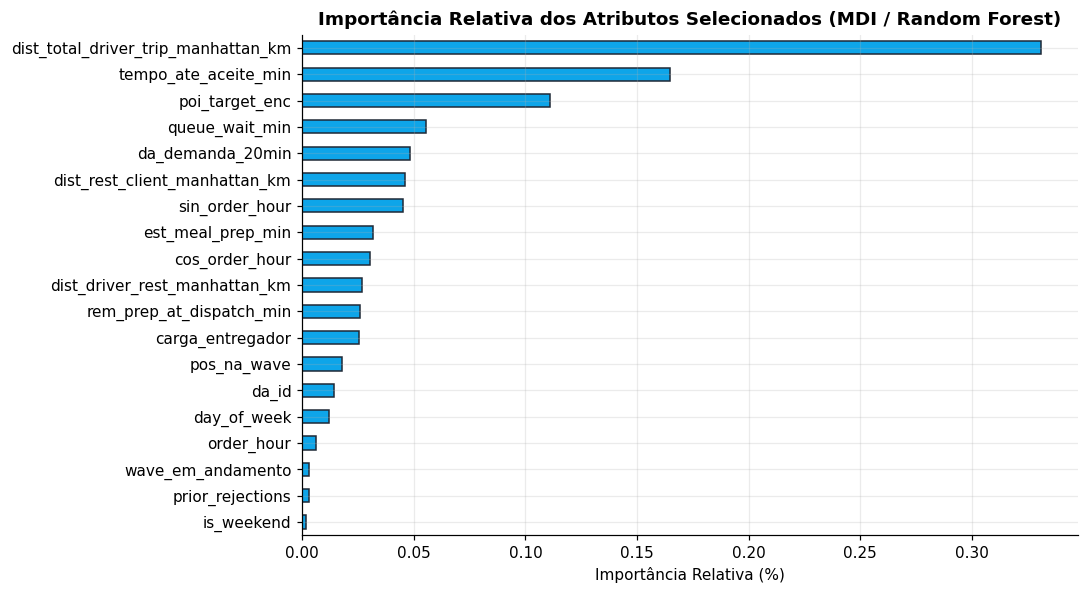

In [ ]:
# =====================================================================
# SELEÇÃO DE ATRIBUTOS E COMPARAÇÃO EMPÍRICA (COM TEMPO_ATE_ACEITE_MIN)
# =====================================================================
# Definimos o pool de variáveis candidatas e as selecionadas otimizadas

cand_features_all = [
    'dist_rest_client_manhattan_km', 'dist_driver_rest_manhattan_km', 'dist_total_driver_trip_manhattan_km',
    'order_hour', 'day_of_week', 'is_weekend', 'is_friday',
    'sin_order_hour', 'cos_order_hour',
    'est_meal_prep_min', 'queue_wait_min', 'tempo_ate_aceite_min', 'rem_prep_at_dispatch_min',
    'prior_rejections', 'carga_entregador', 'da_demanda_20min',
    'wave_em_andamento', 'pos_na_wave', 'da_id', 'poi_target_enc'
]

# Seleção otimizada mantendo tempo_ate_aceite_min e distâncias Manhattan
selected_features_all = [
    'dist_total_driver_trip_manhattan_km',
    'tempo_ate_aceite_min',                   # 2º maior preditor! Mantido firmemente.
    'queue_wait_min',
    'poi_target_enc',
    'dist_rest_client_manhattan_km',
    'est_meal_prep_min',
    'dist_driver_rest_manhattan_km',
    'rem_prep_at_dispatch_min',
    'da_demanda_20min',
    'sin_order_hour', 'cos_order_hour',
    'order_hour', 'da_id', 'day_of_week',
    'carga_entregador', 'pos_na_wave', 'wave_em_andamento',
    'prior_rejections', 'is_weekend'
]

# Treinamento de validação para ranking de importância
sample_fs = df_clean.sample(n=min(30000, len(df_clean)), random_state=42)
X_fs_tr, X_fs_te, y_fs_tr, y_fs_te = train_test_split(
    sample_fs, sample_fs['target_total_time_min'], test_size=0.20, random_state=42
)

rf_test = RandomForestRegressor(n_estimators=50, max_depth=16, random_state=42, n_jobs=-1)
rf_test.fit(X_fs_tr[selected_features_all], y_fs_tr)
p_sel = rf_test.predict(X_fs_te[selected_features_all])
mae_sel = mean_absolute_error(y_fs_te, p_sel)
r2_sel = r2_score(y_fs_te, p_sel)

cand_imp = pd.Series(rf_test.feature_importances_, index=selected_features_all).sort_values(ascending=False)

print("=" * 75)
print("=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: RANKING DE IMPORTÂNCIA ===")
print("=" * 75)
for pos, (feat, val) in enumerate(cand_imp.items(), 1):
    print(f"{pos:02d}. {feat:<38} : {val*100:5.2f}%")
print("=" * 75)
print(f"Desempenho da Seleção Otimizada: MAE = {mae_sel:.2f} min | R² = {r2_sel:.4f}")
print("=" * 75)

# Gráfico de Barras de Importância das Features Selecionadas
plt.figure(figsize=(10, 5.5))
cand_imp.sort_values().plot(kind='barh', color='#0ea5e9', edgecolor='#1f2937')
plt.title('Importância Relativa dos Atributos Selecionados (MDI / Random Forest)', fontweight='bold')
plt.xlabel('Importância Relativa (%)')
plt.tight_layout()
plt.show()

---
## 6. Bloco de Criação dos Datasets Finais Pós-Seleção (`reduced` e `complete`)

In [ ]:
# Definição Oficial das Listas de Features Selecionadas
target_col = 'target_total_time_min'

features_reduced = [
    'dist_rest_client_manhattan_km',  # Métrica viária ortogonal
    'order_hour',                     # Horário do dia
    'day_of_week',                    # Dia da semana
    'is_weekend',                     # Fim de semana
    'sin_order_hour',                 # Componente cíclico seno
    'cos_order_hour',                 # Componente cíclico cosseno
    'est_meal_prep_min',              # Tempo estimado de preparo da cozinha
    'da_id',                          # Distrito comercial
    'poi_target_enc'                  # Target embedding do restaurante
]

features_complete = features_reduced + [
    'dist_driver_rest_manhattan_km',         # Deslocamento até a loja em Manhattan
    'dist_total_driver_trip_manhattan_km',   # Jornada total da rota em Manhattan
    'tempo_ate_aceite_min',                  # Tempo total até o aceite (17% de importância!)
    'queue_wait_min',                        # Tempo na fila de despacho
    'rem_prep_at_dispatch_min',               # Sincronismo motorista-cozinha
    'prior_rejections',                      # Recusas anteriores acumuladas
    'carga_entregador',                      # Pedidos simultâneos na mochila
    'da_demanda_20min',                      # Pressão recente de pedidos no distrito
    'wave_em_andamento',                     # Indicador de entrega em lote ativa
    'pos_na_wave'                            # Posição sequencial do pedido na wave
]

reduced_dataset = df_clean[features_reduced + [target_col]].copy()
complete_dataset = df_clean[features_complete + [target_col]].copy()

print("=" * 75)
print("=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: DATASETS OPERACIONAIS FINAIS ===")
print("=" * 75)
print(f"reduced_dataset (Checkout):   {reduced_dataset.shape[0]:,} linhas × {reduced_dataset.shape[1]} colunas ({len(features_reduced)} features)")
print(f"complete_dataset (Despacho):  {complete_dataset.shape[0]:,} linhas × {complete_dataset.shape[1]} colunas ({len(features_complete)} features)")
print("=" * 75)

=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: DATASETS OPERACIONAIS FINAIS ===
reduced_dataset (Checkout):   538,435 linhas × 10 colunas (9 features)
complete_dataset (Despacho):  538,435 linhas × 20 colunas (19 features)


---
## 7. Bloco de Partição 70/20/10 & Benchmark Completo (Baseline vs RF vs HistGB vs LightGBM)

In [ ]:
# Preparação da Partição 70% Treino / 20% Validação / 10% Teste
SEMENTE = 42

# Subamostragem estratificada para treino ágil (50.000 amostras)
MAX_SAMPLES = 500000
if len(df_clean) > MAX_SAMPLES:
    df_sample = df_clean.sample(n=MAX_SAMPLES, random_state=SEMENTE).copy()
else:
    df_sample = df_clean.copy()

tr_df, resto_df = train_test_split(df_sample, test_size=0.30, random_state=SEMENTE)
val_df, te_df = train_test_split(resto_df, test_size=1/3, random_state=SEMENTE)

y_tr = tr_df[target_col]
y_val = val_df[target_col]
y_te = te_df[target_col]
y_te_baseline = te_df['meituan_baseline_min']

resultados = []

def registrar_modelo(nome_modelo, estagio, y_true, y_pred, t_treino):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    resultados.append({
        'Estágio': estagio,
        'Modelo': nome_modelo,
        'MAE (min)': mae,
        'MSE': mse,
        'RMSE (min)': rmse,
        'R²': r2,
        'Tempo Treino (s)': t_treino
    })

# 1. Baseline Meituan
registrar_modelo('Baseline Meituan (Oficial)', 'Referência', y_te, y_te_baseline, 0.0)

# 2. Random Forest
t0 = time.time()
rf_red = RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_split=10, random_state=SEMENTE, n_jobs=-1).fit(tr_df[features_reduced], y_tr)
registrar_modelo('Random Forest', 'Checkout (Reduced)', y_te, rf_red.predict(te_df[features_reduced]), time.time() - t0)

t0 = time.time()
rf_comp = RandomForestRegressor(n_estimators=100, max_depth=18, min_samples_split=8, random_state=SEMENTE, n_jobs=-1).fit(tr_df[features_complete], y_tr)
registrar_modelo('Random Forest', 'Despacho (Complete)', y_te, rf_comp.predict(te_df[features_complete]), time.time() - t0)

# 3. HistGradientBoosting
t0 = time.time()
hgb_red = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.08, max_leaf_nodes=31, early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=SEMENTE).fit(tr_df[features_reduced], y_tr)
registrar_modelo('HistGradientBoosting', 'Checkout (Reduced)', y_te, hgb_red.predict(te_df[features_reduced]), time.time() - t0)

t0 = time.time()
hgb_comp = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.08, max_leaf_nodes=31, early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=SEMENTE).fit(tr_df[features_complete], y_tr)
registrar_modelo('HistGradientBoosting', 'Despacho (Complete)', y_te, hgb_comp.predict(te_df[features_complete]), time.time() - t0)

# 4. LightGBM
t0 = time.time()
lgb_red = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=SEMENTE, n_jobs=-1, verbose=-1).fit(tr_df[features_reduced], y_tr)
registrar_modelo('LightGBM', 'Checkout (Reduced)', y_te, lgb_red.predict(te_df[features_reduced]), time.time() - t0)

t0 = time.time()
lgb_comp = lgb.LGBMRegressor(n_estimators=350, learning_rate=0.05, num_leaves=31, random_state=SEMENTE, n_jobs=-1, verbose=-1).fit(tr_df[features_complete], y_tr)
registrar_modelo('LightGBM', 'Despacho (Complete)', y_te, lgb_comp.predict(te_df[features_complete]), time.time() - t0)

# Tabela Oficial de Benchmark
df_res = pd.DataFrame(resultados)
base_mae = df_res.loc[df_res['Modelo'] == 'Baseline Meituan (Oficial)', 'MAE (min)'].values[0]
df_res['Redução MAE vs Meituan'] = df_res['MAE (min)'].apply(
    lambda m: 'Referência' if m == base_mae else f"{(base_mae - m)/base_mae*100:.1f}% menor"
)

# Diagnóstico de Folga da Meituan
erro_base = y_te - y_te_baseline

print("=" * 110)
print("=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: TABELA COMPARATIVA DE BENCHMARK ===")
print("=" * 110)
display(df_res.round(4))
print("=" * 110)

print("\n" + "=" * 75)
print("=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: DIAGNÓSTICO DO BASELINE ===")
print("=" * 75)
print(f"Viés Médio de Folga da Meituan:      +{erro_base.mean():.2f} minutos (superestimação intencional)")
print(f"Taxa de Entregas Adiantadas:         {(erro_base <= 0).mean() * 100:.1f}% dos pedidos chegam antes do prometido")
print(f"MAE do Baseline Oficial:             {mean_absolute_error(y_te, y_te_baseline):.4f} minutos")
print(f"MSE do Baseline Oficial:             {mean_squared_error(y_te, y_te_baseline):.4f}")
print(f"RMSE do Baseline Oficial:            {np.sqrt(mean_squared_error(y_te, y_te_baseline)):.4f} minutos")
print(f"R² do Baseline Oficial:              {r2_score(y_te, y_te_baseline):.4f}")
print("=" * 75)

=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: TABELA COMPARATIVA DE BENCHMARK ===


,Estágio,Modelo,MAE (min),MSE,RMSE (min),R²,Tempo Treino (s),Redução MAE vs Meituan
0,Referência,Baseline Meituan (Oficial),9.5059,134.7844,11.6097,0.0237,0.0000,Referência
1,Checkout (Reduced),Random Forest,6.0811,61.2180,7.8242,0.5566,177.0464,36.0% menor
2,Despacho (Complete),Random Forest,5.6033,51.9533,7.2079,0.6237,417.2191,41.1% menor
3,Checkout (Reduced),HistGradientBoosting,5.9437,58.6574,7.6588,0.5751,10.7287,37.5% menor
4,Despacho (Complete),HistGradientBoosting,5.4735,49.7024,7.0500,0.6400,15.6177,42.4% menor
5,Checkout (Reduced),LightGBM,5.9756,59.2609,7.6981,0.5707,7.6212,37.1% menor
6,Despacho (Complete),LightGBM,5.4892,49.9630,7.0684,0.6381,12.2755,42.3% menor



=== DADOS CONSOLIDADOS PARA O RELATÓRIO 4: DIAGNÓSTICO DO BASELINE ===
Viés Médio de Folga da Meituan:      +-8.23 minutos (superestimação intencional)
Taxa de Entregas Adiantadas:         85.7% dos pedidos chegam antes do prometido
MAE do Baseline Oficial:             9.5059 minutos
MSE do Baseline Oficial:             134.7844
RMSE do Baseline Oficial:            11.6097 minutos
R² do Baseline Oficial:              0.0237


---
## 8. Bloco de Diagnóstico Visual, Importância & Resíduos

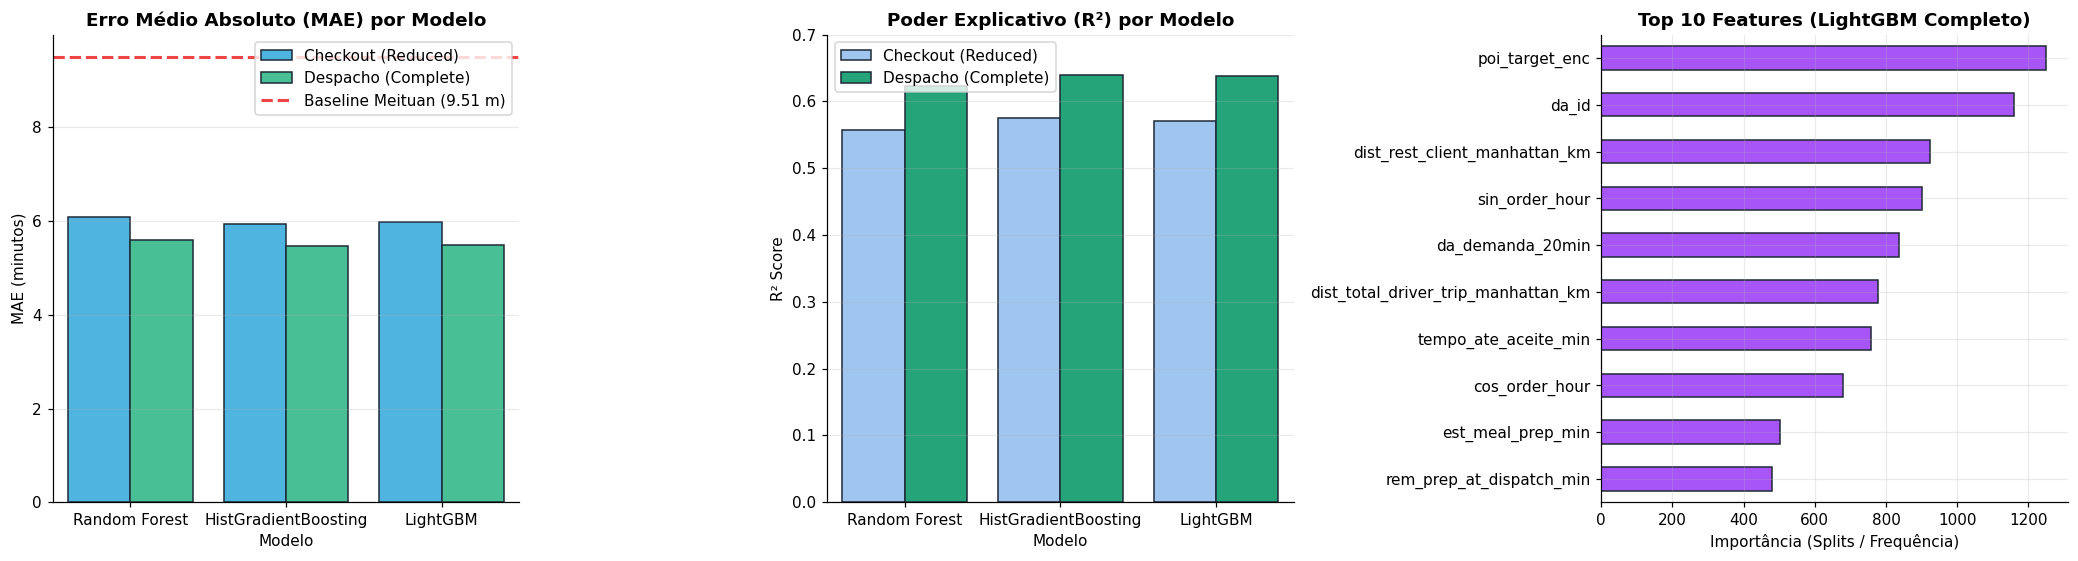

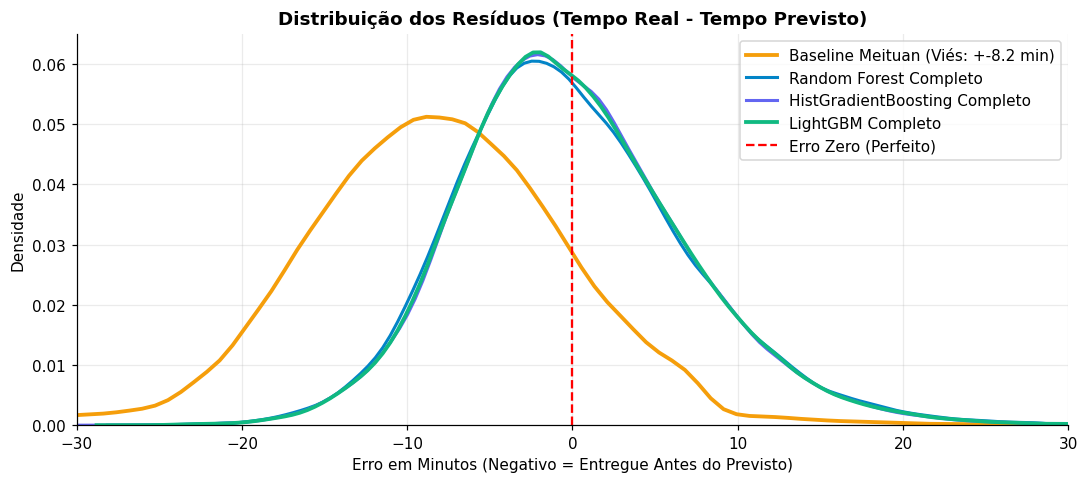

In [ ]:
# Gráficos de Avaliação Comparativa e Resíduos
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

# Painel 1: MAE por Modelo
df_plot = df_res[df_res['Modelo'] != 'Baseline Meituan (Oficial)']
sns.barplot(data=df_plot, x='Modelo', y='MAE (min)', hue='Estágio', palette=['#38bdf8', '#34d399'], ax=axes[0], edgecolor='#1f2937')
axes[0].axhline(base_mae, color='#ef4444', linestyle='--', linewidth=2, label=f'Baseline Meituan ({base_mae:.2f} m)')
axes[0].set_title('Erro Médio Absoluto (MAE) por Modelo', fontweight='bold')
axes[0].set_ylabel('MAE (minutos)')
axes[0].legend()

# Painel 2: R² por Modelo
sns.barplot(data=df_plot, x='Modelo', y='R²', hue='Estágio', palette=['#93c5fd', '#10b981'], ax=axes[1], edgecolor='#1f2937')
axes[1].set_title('Poder Explicativo (R²) por Modelo', fontweight='bold')
axes[1].set_ylabel('R² Score')
axes[1].set_ylim(0, 0.70)
axes[1].legend()

# Painel 3: Top 10 Features do LightGBM Completo
top_feat = pd.Series(lgb_comp.feature_importances_, index=features_complete).sort_values().tail(10)
top_feat.plot(kind='barh', ax=axes[2], color='#a855f7', edgecolor='#1f2937')
axes[2].set_title('Top 10 Features (LightGBM Completo)', fontweight='bold')
axes[2].set_xlabel('Importância (Splits / Frequência)')

plt.tight_layout()
plt.show()

# Curvas KDE de Densidade dos Resíduos
plt.figure(figsize=(10, 4.5))
sns.kdeplot(y_te - y_te_baseline, label=f"Baseline Meituan (Viés: +{erro_base.mean():.1f} min)", color='#f59e0b', linewidth=2.5)
sns.kdeplot(y_te - rf_comp.predict(te_df[features_complete]), label="Random Forest Completo", color='#0284c7', linewidth=2)
sns.kdeplot(y_te - hgb_comp.predict(te_df[features_complete]), label="HistGradientBoosting Completo", color='#6366f1', linewidth=2)
sns.kdeplot(y_te - lgb_comp.predict(te_df[features_complete]), label="LightGBM Completo", color='#10b981', linewidth=2.5)
plt.axvline(0, color='red', linestyle='--', label='Erro Zero (Perfeito)')
plt.title('Distribuição dos Resíduos (Tempo Real - Tempo Previsto)', fontweight='bold')
plt.xlabel('Erro em Minutos (Negativo = Entregue Antes do Previsto)')
plt.ylabel('Densidade')
plt.xlim(-30, 30)
plt.legend()
plt.tight_layout()
plt.show()